# PoC · Asistente de apoyo al psicodiagnóstico (LC-B + LC-C)
**Kit PoC · Colab + LangChain + OpenRouter** · Etapa 1: entrada de texto

Flujo: el texto se **anonimiza** (NER local; nombres, lugares y organizaciones no salen de la VM) →
**guardrail** de contexto clínico (`respan/span-01-lite:free`) → **extraer** síntomas →
**agente CIE-11** (MCP en Azure) → **reporte** Markdown con código y liga OMS.

1. Abre este cuaderno en Colab y monta Google Drive cuando lo pida (la carpeta `poc_psicodiagnostico` debe estar en tu Drive).
2. Guarda `OPENROUTER_API_KEY` en los Secretos de Colab (acceso del notebook activado) o, en local, en el archivo `.env`.
3. Ejecuta todo. Una corrida completa usa cerca de 8 llamadas al modelo; la cuenta gratuita permite 50 por día.

> Trabaja solo con datos sintéticos o anonimizados: el endpoint gratuito del modelo registra el uso.

## 0 · Instalación, Drive y clave (no editar)

In [1]:
# 0.1 · Dependencias (no editar). En Colab se instalan aquí; en local vienen de uv sync (ver README)
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-qU",
        "langchain>=1.4,<2", "langchain-openai>=1.6,<2", "langgraph>=1.2,<2",
        "langchain-mcp-adapters", "transformers", "torch", "pydantic", "requests", "pandas",
    ])
else:
    print("Entorno local: las dependencias vienen de uv sync (ver README).")

Entorno local: las dependencias vienen de uv sync (ver README).


In [2]:
# 0.2 · Drive y ruta del paquete poc_psico (no editar)
import os
import sys

RUTA_PROYECTO = "/content/drive/MyDrive/LLM solutions architect/Módulo 5/poc_psicodiagnostico"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    RUTA_PROYECTO = os.getcwd()
sys.path.insert(0, RUTA_PROYECTO)
from poc_psico import grafo  # falla aquí si la ruta no es correcta
print("Paquete cargado desde", RUTA_PROYECTO)

Paquete cargado desde /Users/dalia/Library/CloudStorage/GoogleDrive-daliaf172@gmail.com/Mi unidad/LLM solutions architect/Módulo 5/poc_psicodiagnostico


In [3]:
# 0.3 · Clave de OpenRouter (no editar). Colab: Secretos. Local: archivo .env (ver README)
import getpass
from poc_psico.entorno import cargar_env

if cargar_env(os.path.join(RUTA_PROYECTO, ".env")):
    print("Variables cargadas desde .env")

def leer_secreto(nombre: str, obligatorio: bool = True):
    try:
        from google.colab import userdata
        valor = userdata.get(nombre)
        if valor:
            return valor
    except Exception:
        pass
    if os.environ.get(nombre):
        return os.environ[nombre]
    if obligatorio:
        return getpass.getpass(f"Pega tu {nombre}: ")
    return None

os.environ["OPENROUTER_API_KEY"] = leer_secreto("OPENROUTER_API_KEY")
langsmith_key = leer_secreto("LANGSMITH_API_KEY", obligatorio=False)
if langsmith_key:
    os.environ["LANGSMITH_API_KEY"] = langsmith_key
    os.environ["LANGSMITH_TRACING"] = "true"
    os.environ["LANGSMITH_PROJECT"] = "kit-poc"
print("Clave cargada. LangSmith:", "activo" if langsmith_key else "desactivado")

Variables cargadas desde .env
Clave cargada. LangSmith: desactivado


## 1 · Modelo y NER (no editar)

In [4]:
# 1.1 · Modelo único del curso: OpenRouter + NVIDIA Nemotron 3 Ultra (no editar)
from langchain_openai import ChatOpenAI
from langchain_core.globals import set_llm_cache
from langchain_core.caches import InMemoryCache

TEMPLATE_ID = "LC-B+C"
# MODEL_ID = "nvidia/nemotron-3-ultra-550b-a55b:free"
MODEL_ID = "anthropic/claude-haiku-5.5"
set_llm_cache(InMemoryCache())

llm = ChatOpenAI(
    model=MODEL_ID,
    api_key=os.environ["OPENROUTER_API_KEY"],
    base_url="https://openrouter.ai/api/v1",
    temperature=0,
    max_tokens=4096,
    timeout=120,
    max_retries=3,
    default_headers={"HTTP-Referer": "https://colab.research.google.com", "X-Title": "Kit PoC BSG"},
)

def texto(mensaje) -> str:
    return mensaje.text if hasattr(mensaje, "text") else str(mensaje.content)

print("Prueba de conexión:", texto(llm.invoke("Responde solo con la palabra OK.")))

Prueba de conexión: OK


In [5]:
# 1.2 · Modelo NER en español (corre en la VM de Colab; no usa API externa)
from transformers import pipeline

ner_es = pipeline("ner", model="MMG/xlm-roberta-large-ner-spanish", aggregation_strategy="simple")
print(ner_es("Mi nombre es Dalia Camacho y vivo en CDMX"))

/Users/dalia/.venvs/poc_psico/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 7279.42it/s]


[{'entity_group': 'PER', 'score': np.float32(0.9827172), 'word': 'Dalia Camacho', 'start': 13, 'end': 26}, {'entity_group': 'LOC', 'score': np.float32(0.90801215), 'word': 'CDMX', 'start': 37, 'end': 41}]


## 2 · Tu caso (EDITA AQUÍ)

In [6]:
# EDITA AQUÍ · 2.1 Guardrail, MCP y agente
UMBRAL_GUARDRAIL = 0.5          # probabilidad mínima de "contexto de psicología clínica"
AGENT_MCP_URL = os.getenv(
    "AGENT_MCP_URL",
    "https://cie11-mcp-server.orangerock-5a17ced7.eastus.azurecontainerapps.io/sse",
)
from poc_psico.agente import TOOLS_BASE, TOOLS_CON_SINTOMAS, PROMPT_AGENTE
TOOLS_PERMITIDAS = TOOLS_BASE   # prueba también TOOLS_CON_SINTOMAS y compara las rondas
SYSTEM_PROMPT_AGENTE = PROMPT_AGENTE
MAX_RONDAS = 5                 # rondas de tools que puede dar el agente (el agente ve cuántas lleva)
# OCR de fotos manuscritas: "mistral" (OpenRouter, unos 4 s; la foto sale a OpenRouter y Mistral antes de anonimizar)
# o "local" (Ollama con qwen2.5vl:3b, unos 40 a 50 s; la foto no sale de tu equipo, solo en Jupyter local)
OCR_MOTOR = "mistral"
# Guías clínicas de apa.org (plugin web de OpenRouter, filtrado al dominio; solo viajan los títulos CIE-11, nunca datos del paciente).
# Cuesta una búsqueda extra por caso; si falla, el reporte sale sin guías y con una advertencia.
BUSCAR_GUIAS_APA = True

In [7]:
# EDITA AQUÍ · 2.2 Contrato de síntomas y de reporte
# Los contratos Pydantic y los prompts del extractor y del redactor están en
# poc_psico/esquemas.py y poc_psico/nodos.py; edítalos ahí y reinicia el entorno.
from poc_psico.esquemas import SintomasPaciente, ReporteClinico
print("Síntomas:", list(SintomasPaciente.model_fields))
print("Reporte:", list(ReporteClinico.model_fields))

Síntomas: ['paciente_ref', 'edad', 'sexo', 'cognitivos', 'emocionales', 'conductuales', 'afectacion_social', 'temporalidad', 'datos_faltantes']
Reporte: ['hipotesis', 'ambiguedades', 'diferenciales', 'datos_faltantes', 'pruebas']


In [8]:
# EDITA AQUÍ · 2.3 Casos de prueba (sintéticos)
from poc_psico.casos import CASOS
print(f"{len(CASOS)} casos:", [c["id"] for c in CASOS])

4 casos: ['P1', 'P2', 'P3', 'P4']


## 3 · Construcción del flujo (no editar)

In [9]:
# 3.1 · Componentes y grafo (no editar)
from poc_psico.agente import cargar_tools, construir_agente, correr_agente
from poc_psico.grafo import Componentes, construir_workflow, ejecutar
from poc_psico.guardrail import consultar_decisions
from poc_psico.guias import buscar_guias_apa
from poc_psico.nodos import crear_extractor, crear_redactor
from poc_psico.ocr import leer_imagen, leer_imagen_mistral

tools = await cargar_tools(AGENT_MCP_URL, TOOLS_PERMITIDAS)
agente = construir_agente(llm, tools, SYSTEM_PROMPT_AGENTE, MAX_RONDAS)

async def _agente(sintomas):
    return await correr_agente(agente, sintomas, MAX_RONDAS)

def _ocr(ruta):
    if OCR_MOTOR == "local":
        return leer_imagen(ruta)
    return leer_imagen_mistral(ruta, os.environ["OPENROUTER_API_KEY"])

def _guardrail(texto):
    return consultar_decisions(texto, os.environ["OPENROUTER_API_KEY"])

def _guias(candidatos):
    return buscar_guias_apa(candidatos, os.environ["OPENROUTER_API_KEY"])

componentes = Componentes(
    ner=ner_es,
    guardrail=_guardrail,
    extraer=crear_extractor(llm),
    agente=_agente,
    redactar=crear_redactor(llm),
    umbral=UMBRAL_GUARDRAIL,
    ocr=_ocr,
    guias=_guias if BUSCAR_GUIAS_APA else None,
)
print("Tools:", [t.name for t in tools])

Tools: ['icd11_buscar_fundacion', 'icd11_buscar_codigo_mms', 'icd11_obtener_criterios_clinicos']


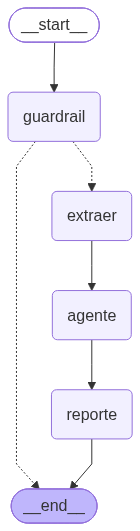

In [10]:
# 3.2 · Dibujo del workflow (no editar)
try:
    from IPython.display import Image, display
    display(Image(construir_workflow(componentes, {}).get_graph().draw_mermaid_png()))
except Exception:
    print(construir_workflow(componentes, {}).get_graph().draw_mermaid())

## 4 · Pruebas y evidencia (no editar)

In [11]:
# 4.1 · Ejecuta los casos y registra la evidencia (no editar)
import json
import time
import pandas as pd

def describir(r: dict) -> str:
    if r is None:
        return ""
    resumen = {
        "estado": r["estado_final"], "razon": r["razon"], "prob_clinico": r["prob_clinico"],
        "codigos": [c["codigo"] for c in r["candidatos"]], "rondas_agente": r["rondas_agente"], "guias_apa": len(r["guias"]),
        "latencias_s": r["latencias"], "advertencias": r["advertencias"],
    }
    return json.dumps(resumen, ensure_ascii=False)

def rondas_de(observado: str):
    return json.loads(observado)["rondas_agente"] if observado else None

async def correr_casos(casos, componentes):
    filas = []
    for caso in casos:
        print(f"→ {caso['id']} · {caso['tipo']}")
        inicio = time.perf_counter()
        resultado, error = None, ""
        try:
            resultado = await ejecutar(caso["entrada"], componentes)
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
        latencia = round(time.perf_counter() - inicio, 2)
        try:
            paso = resultado is not None and bool(caso["verificar"](resultado))
        except Exception as exc:
            paso, error = False, error or f"Error al verificar: {exc}"
        filas.append({
            "template": TEMPLATE_ID, "id": caso["id"], "tipo": caso["tipo"], "entrada": caso["entrada"],
            "esperado": caso["esperado"], "criterio": caso["criterio"], "observado": describir(resultado),
            "veredicto_auto": "PASS" if paso else "FAIL", "veredicto_final": "",
            "latencia_s": latencia, "error": error,
        })
    return pd.DataFrame(filas)

registro = await correr_casos(CASOS, componentes)
pd.set_option("display.max_colwidth", 220)
vista = registro.assign(rondas=registro["observado"].map(rondas_de))
display(vista[["id", "tipo", "veredicto_auto", "rondas", "latencia_s", "observado", "error"]])
print(f"\nResultado automático: {(registro.veredicto_auto == 'PASS').sum()} de {len(registro)} casos en PASS")

→ P1 · caso completo
→ P2 · datos ausentes


Salida con formato inválido: reintento 1 de 2


→ P3 · fuera de contexto
→ P4 · instrucciones inyectadas


,id,tipo,veredicto_auto,rondas,latencia_s,observado,error
0,P1,caso completo,PASS,2,32.56,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.92950356, ""codigos"": [""6A70.1"", ""6A72"", ""6B43""], ""rondas_agente"": 2, ""latencias_s"": {""anonimizar"": 0.922, ""guardrail"": 0.238, ""extraer"": 2.505, ""agente"": 19.567, ""repor...",
1,P2,datos ausentes,PASS,2,47.02,"{""estado"": ""ok"", ""razon"": """", ""prob_clinico"": 0.92396104, ""codigos"": [""6A70.0"", ""6A70.1"", ""6A72"", ""7A00"", ""7A01""], ""rondas_agente"": 2, ""latencias_s"": {""anonimizar"": 1.277, ""guardrail"": 0.4, ""extraer"": 1.945, ""agente""...",
2,P3,fuera de contexto,PASS,0,1.85,"{""estado"": ""fuera_de_alcance"", ""razon"": ""Probabilidad de contexto clínico 0.017926477 por debajo del umbral 0.5"", ""prob_clinico"": 0.017926477, ""codigos"": [], ""rondas_agente"": 0, ""latencias_s"": {""anonimizar"": 1.488, ""...",
3,P4,instrucciones inyectadas,PASS,0,1.08,"{""estado"": ""fuera_de_alcance"", ""razon"": ""Probabilidad de contexto clínico 0.03213016 por debajo del umbral 0.5"", ""prob_clinico"": 0.03213016, ""codigos"": [], ""rondas_agente"": 0, ""latencias_s"": {""anonimizar"": 0.873, ""gu...",



Resultado automático: 4 de 4 casos en PASS


In [12]:
# 4.2 · Guarda el registro de pruebas (no editar)
archivo = f"registro_pruebas_{TEMPLATE_ID}.csv"
registro.to_csv(archivo, index=False, encoding="utf-8-sig")
print("Registro guardado:", archivo)

Registro guardado: registro_pruebas_LC-B+C.csv


In [13]:
# 4.3 · Falla de conexión al MCP: el flujo debe detenerse sin reporte (no editar)
from poc_psico.agente import cargar_tools
from poc_psico.errores import FlujoDetenido

async def _agente_roto(sintomas):
    await cargar_tools("https://no-existe.invalid/sse", TOOLS_PERMITIDAS)

roto = Componentes(ner=ner_es, guardrail=_guardrail, extraer=crear_extractor(llm), agente=_agente_roto,
                   redactar=crear_redactor(llm), umbral=UMBRAL_GUARDRAIL)
r = await ejecutar(CASOS[0]["entrada"], roto)
assert r["estado_final"] == "error" and r["reporte_md"] == "", r
print("OK, se detuvo con:", r["razon"])

OK, se detuvo con: No se pudo conectar al MCP CIE-11 (https://no-existe.invalid/sse): unhandled errors in a TaskGroup (1 sub-exception)


## 5 · Prueba libre y reporte

In [14]:
# 5 · Prueba libre: escribe tu viñeta sintética
entrada = "Paciente de 41 años con ánimo irritable, preocupación constante y tensión muscular desde hace 8 meses."
r = await ejecutar(entrada, componentes)
print(r["estado_final"], "|", r["razon"])
from IPython.display import Markdown
Markdown(r["reporte_md"]) if r["reporte_md"] else None

ok | 


# Reporte de apoyo al psicodiagnóstico

## 1. Datos del caso

- Paciente: No identificado

- Edad: 41

- Sexo: No indicado

- Temporalidad: desde hace 8 meses

- Fecha del reporte: 2026-10-15

## 2. Síntomas por categoría

### Cognitivos

- Ninguno identificado

### Emocionales

- Ánimo irritable
- Preocupación constante

### Conductuales

- Tensión muscular

### Afectación social

- Ninguno identificado

## 3. Hipótesis diagnósticas (de la más a la menos plausible)

### 1. Trastorno de ansiedad generalizada — `6B00`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#1712535455)

**Justificación:** El cuadro de preocupación constante con irritabilidad y tensión muscular que persiste unos 8 meses es compatible con la descripción del trastorno de ansiedad generalizada. La definición exige preocupación excesiva sobre múltiples eventos cotidianos, síntomas adicionales (tensión, irritabilidad, dificultad de concentración o alteraciones del sueño) y deterioro funcional. Los datos disponibles cubren solo parte de estos criterios, por lo que el diagnóstico no puede confirmarse todavía.

**Criterios cumplidos:**

- Preocupación constante, asociada a síntomas de ansiedad
- Tensión muscular
- Irritabilidad
- Duración de aproximadamente 8 meses, por encima del umbral de varios meses

**Criterios no cumplidos o sin confirmar:**

- Frecuencia de los síntomas (más días con síntomas que sin ellos) no confirmada
- Temas de preocupación (familia, salud, finanzas, trabajo) no especificados
- Deterioro o angustia significativos no confirmados
- Concentración, sueño y actividad autonómica no evaluados
- Exclusión de causa médica y de sustancias pendiente

### 2. Trastorno de adaptación — `6B43`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

**Justificación:** La preocupación y el malestar podrían corresponder a una reacción a un estresor, pero el caso no aporta ningún factor estresante identificable ni un inicio temporal ligado a un evento. Además, su duración de 8 meses supera el curso habitual del trastorno de adaptación sin un estresor que persista. Solo podría considerarse si aparece un estresor claro al explorar la historia.

**Criterios cumplidos:**

- Preocupación y malestar persistentes
- Cuadro de varios meses de evolución

**Criterios no cumplidos o sin confirmar:**

- Estresor psicosocial identificable no consta
- Inicio dentro del mes posterior al estresor no verificado
- Duración habitual de hasta 6 meses, salvo persistencia del estresor, no encaja con 8 meses sin estresor conocido
- Deterioro funcional no documentado

### Ambigüedades

- Sexo del paciente no consta
- Severidad de los síntomas no consta
- No está claro si la preocupación es excesiva y generalizada o se limita a un tema
- No se sabe si el malestar causa deterioro funcional
- El agente no obtuvo resultados para 'preocupación excesiva' en la búsqueda
- La irritabilidad sugiere revisar trastornos del estado de ánimo, que no se consultaron
- Las listas de inclusiones y exclusiones de 6B00 están vacías

## 4. Diferenciales y exclusiones

- Trastorno de adaptación (6B43): requiere estresor identificable y suele resolverse en 6 meses
- Trastornos depresivos: la irritabilidad y el malestar sugieren descartar un episodio depresivo
- Causa médica o efecto de sustancias o medicamentos sobre el sistema nervioso central
- Otros trastornos de ansiedad (fobias, trastorno de pánico, trastorno obsesivo-compulsivo) si la preocupación se centra en un tema concreto
- Trastornos específicamente asociados con el estrés, sin especificación (6B4Z), descartado por el agente de búsqueda
- Otras alternativas descartadas: 4A01.Z, 6B06 y 6E20/6B43, sin datos que las justifiquen

### Alternativas consultadas y descartadas

- Inmunodeficiencias primarias por trastornos de la inmunidad adaptativa, sin especificación (`4A01.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1169765917%2Funspecified)

- Trastornos específicamente asociados con el estrés, sin especificación (`6B4Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#991786158%2Funspecified)

- Mutismo selectivo (`6B06`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#167946871)

- Trastornos mentales o del comportamiento asociados con el embarazo, el parto o el puerperio, sin síntomas psicóticos [Trastorno de adaptación] (`6E20/6B43`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

## 5. Datos faltantes por recabar

- Sexo del paciente
- Severidad de los síntomas
- Impacto funcional en trabajo, familia o relaciones
- Síntomas cognitivos (concentración, memoria)
- Calidad del sueño
- Antecedentes psiquiátricos y médicos
- Consumo de sustancias o medicamentos
- Factores desencadenantes o eventos estresantes
- Frecuencia de los días con preocupación
- Temas concretos de preocupación
- Síntomas de ánimo deprimido, anhedonia o sintomatología depresiva asociada
- Síntomas somáticos autonómicos (palpitaciones, sudoración, molestias gastrointestinales)
- Historia de episodios de ansiedad o depresión previos
- Evaluación de posibles causas médicas (tiroides, cafeína, otras)

## 6. Pruebas complementarias sugeridas

> Sugerencias a validar por el profesional. Solo se indica el nombre de la prueba: no se incluyen cuestionarios ni formas de calificación.

- **Inventario de Ansiedad de Beck**: Cuantifica la severidad de los síntomas de ansiedad y permite seguir su evolución.

- **Escala de Ansiedad Generalizada GAD-7**: Ofrece un cribado breve de ansiedad generalizada y su severidad.

- **Inventario de Depresión de Beck**: Permite descartar o detectar sintomatología depresiva asociada a la irritabilidad y al malestar.

- **Entrevista clínica estructurada para trastornos de ansiedad (SCID-5-TR, módulo de ansiedad)**: Verifica sistemáticamente la duración, frecuencia y deterioro funcional necesarios para el diagnóstico.

- **Índice de Calidad del Sueño de Pittsburgh**: Evalúa el sueño, un criterio asociado que aún no se ha explorado.

## 7. Aviso

Este reporte contiene hipótesis de apoyo generadas con ayuda de IA a partir de la CIE-11. No es un diagnóstico: la decisión clínica es del profesional.


In [15]:
# 5.1 · Prueba con foto de una nota manuscrita (motor en OCR_MOTOR, celda 2.1; ver README)
RUTA_FOTO = "data/caso1_m_28.jpeg"  # EDITA AQUÍ: ruta a tu foto .jpg o .png; déjalo vacío para omitir
from IPython.display import Markdown

r = await ejecutar(RUTA_FOTO, componentes)
print("Texto leído (revísalo: un error de lectura cambia el sentido clínico):\n", r["texto_ocr"])
print(r["estado_final"], "|", r["razon"], "|", r["latencias"])
Markdown(r["reporte_md"]) if r["reporte_md"] else None

Texto leído (revísalo: un error de lectura cambia el sentido clínico):
 LUCTA 28 AÑOS

Vive con sus padres
Tiene 3 hermanos mayores

Refiere ansiedad al
estar en situaciones donde
hay mucha gente

Le cuesta trabajo hablam
con desconocidos. Refiere
que nosasiente escuchada en
casa y nunca ha creído
tener un lugar para poder
dar su opinión.

Terminó con su novio
hace 2 meses y desde eso
menos quiere salir de
casa e interactuar.
Hay días que tampoco
quiere levantarse en la
trabajo y que les fue
sólo duerme.
ok |  | {'ocr': 2.878, 'anonimizar': 1.251, 'guardrail': 0.36, 'extraer': 3.293, 'agente': 16.191, 'reporte': 10.825}


# Reporte de apoyo al psicodiagnóstico

## 1. Datos del caso

- Paciente: LU

- Edad: 28

- Sexo: No indicado

- Temporalidad: "Ruptura de noviazgo hace 2 meses; desde entonces disminución de ganas de salir e interactuar y algunos días sin querer levantarse para ir a trabajar"

- Fecha del reporte: 2026-10-15

## 2. Síntomas por categoría

### Cognitivos

- Ninguno identificado

### Emocionales

- Ansiedad en situaciones con mucha gente
- Sensación de no ser escuchada en casa
- Sensación de no tener un lugar para dar su opinión

### Conductuales

- Dificultad para hablar con desconocidos
- Menor deseo de salir de casa e interactuar
- Días en que no quiere levantarse de la cama

### Afectación social

- Vive con sus padres y tiene 3 hermanos mayores
- Dificultad para interactuar socialmente desde la ruptura
- Afectación en el trabajo: días en que no quiere ir a trabajar

## 3. Hipótesis diagnósticas (de la más a la menos plausible)

### 1. Trastorno de adaptación — `6B43`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

**Justificación:** Inicio de los síntomas tras una ruptura de noviazgo hace 2 meses (estresante psicosocial identificable, dentro del plazo de un mes-tres meses habitual). Hay retraimiento social, menor deseo de salir, dificultad para interactuar desde la ruptura y días sin querer levantarse ni ir a trabajar, con deterioro laboral. Encaja con una reacción desadaptativa al estrés vivido.

**Criterios cumplidos:**

- Estresante psicosocial identificable (ruptura de noviazgo)
- Inicio de los síntomas tras el factor estresante (hace 2 meses)
- Preocupación o cavilación por el factor estresante (no detallada en el JSON, pero compatible con la sensación de no ser escuchada)
- Deterioro en la vida social y laboral (dificultad para interactuar, días sin ir a trabajar)

**Criterios no cumplidos o sin confirmar:**

- Confirmar preocupación o pensamientos recurrentes sobre la ruptura
- Confirmar que los síntomas no se explican mejor por un trastorno depresivo ni por ansiedad social previa
- Duración: se resuelve en 6 meses salvo que el estresante persista

### 2. Trastorno de ansiedad social — `6B04`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#2062286624)

**Justificación:** Ansiedad en situaciones con mucha gente y dificultad para hablar con desconocidos, con evitación creciente de la interacción social. Estas son las situaciones sociales típicas del trastorno de ansiedad social.

**Criterios cumplidos:**

- Miedo o ansiedad ante situaciones sociales (gente numerosa, hablar con desconocidos)
- Evitación o retraimiento social (menor deseo de salir e interactuar)
- Deterioro social y laboral reportado

**Criterios no cumplidos o sin confirmar:**

- Persistencia de al menos varios meses: solo hay 2 meses de síntomas desde la ruptura; la duración previa es dato faltante
- Miedo a ser evaluada negativamente: no explorado
- Severidad de la ansiedad: no descrita

### 3. Trastorno depresivo de episodio único, sin especificación — `6A70.Z`

[Abrir en el navegador OMS](https://icd.who.int/browse/2026-01/mms/es#578635574%2Funspecified)

**Justificación:** Los síntomas de desánimo, retraimiento y días sin querer levantarse podrían corresponder a un episodio depresivo único. No se puede evaluar con los datos, porque la búsqueda no devolvió definición ni criterios para esta entidad.

**Criterios cumplidos:**

- Cambio en el interés y la motivación para salir e interactuar (posible anhedonia, no confirmada)
- Días sin querer levantarse (posible síntoma depresivo, no confirmado)

**Criterios no cumplidos o sin confirmar:**

- Estado de ánimo deprimido o anhedonia no explorados
- Duración mínima de 2 semanas no confirmada en el JSON (sí podría cumplirse, 2 meses)
- Número de síntomas y severidad no evaluados
- Sin definición disponible para contrastar criterios

### Ambigüedades

- Los tres diagnósticos candidatos son posibles y no se pueden diferenciar con los datos disponibles
- La duración de la ansiedad social antes de la ruptura no está clara
- No se sabe si la ansiedad social existía antes de la ruptura o aparece con ella
- El texto dice que solo duerme, sin detallar la calidad ni las horas de sueño
- Frecuencia de los días sin levantarse y de las faltas al trabajo no precisada
- Definición e criterios de 6A70.Z no disponibles en la búsqueda
- Sexo no indicado en el JSON

## 4. Diferenciales y exclusiones

- Trastorno de adaptación (6B43) frente a trastorno de ansiedad social (6B04): distinguir si la ansiedad social precede a la ruptura o surge con ella
- Trastorno depresivo de episodio único sin especificación (6A70.Z) frente a trastorno de adaptación: el trastorno de adaptación excluye trastorno depresivo
- Duelo sin complicaciones y trastorno por duelo prolongado: excluidos en 6B43, revisar si la ruptura se vive como pérdida
- Reacción aguda al estrés: descartable por la duración de 2 meses
- Trastornos específicamente asociados con el estrés sin especificación (6B4Z): alternativa descartada, reservar si no encaja otro
- Mutismo selectivo (6B06): descartado, no hay mutismo
- Trastornos depresivos recurrentes (6A71.Z) y episodio persistente (6A80.2): descartados sin antecedentes; confirmar historial
- Consumo de sustancias y trastornos del sueño como causas alternativas o concurrentes

### Alternativas consultadas y descartadas

- Trastornos específicamente asociados con el estrés, sin especificación (`6B4Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#991786158%2Funspecified)

- Mutismo selectivo (`6B06`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#167946871)

- Trastornos mentales o del comportamiento asociados con el embarazo, el parto o el puerperio, sin síntomas psicóticos [Trastorno de adaptación] (`6E20/6B43`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#264310751)

- Trastorno depresivo de episodio único, moderado, sin síntomas psicóticos (`6A70.1`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#399670840)

- Otro trastorno depresivo de episodio único, especificado (`6A70.Y`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#578635574%2Fother)

- Trastorno depresivo recurrente, sin especificación (`6A71.Z`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1194756772%2Funspecified)

- Episodio depresivo actual persistente (`6A80.2`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1906190365)

- Episodio depresivo actual con melancolía (`6A80.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#802537726)

- Trastorno depresivo, episodio único grave sin síntomas psicóticos (`6A70.3`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1669279433)

- Trastorno depresivo de episodio único, leve (`6A70.0`) — [OMS](https://icd.who.int/browse/2026-01/mms/es#1922675618)

## 5. Datos faltantes por recabar

- Severidad de la ansiedad
- Duración de los síntomas de ansiedad social antes de la ruptura
- Estado de ánimo y presencia de tristeza o anhedonia
- Ideación suicida o riesgo
- Consumo de sustancias
- Calidad y horas de sueño
- Frecuencia de faltas al trabajo
- Antecedentes psiquiátricos y familiares
- Relación con padres y hermanos
- Apoyo social fuera de la familia
- Impacto funcional detallado en trabajo y vida diaria
- Edad confirmada: 28 años
- Sexo del paciente
- Preocupación o rumiación sobre la ruptura
- Duración exacta de los síntomas
- Comorbilidad médica

## 6. Pruebas complementarias sugeridas

> Sugerencias a validar por el profesional. Solo se indica el nombre de la prueba: no se incluyen cuestionarios ni formas de calificación.

- **Entrevista clínica estructurada para trastornos de ansiedad y del estado de ánimo (SCID-5-CV o equivalente)**: Permite evaluar de forma sistemática la presencia, duración y temporalidad de los síntomas de ansiedad social y depresivos.

- **Escala de Ansiedad Social de Liebowitz**: Mide la severidad de la ansiedad en distintas situaciones sociales y ayuda a valorar el impacto funcional.

- **Inventario de Depresión de Beck**: Ayuda a cuantificar la presencia y severidad de síntomas depresivos para diferenciar entre depresión y trastorno de adaptación.

- **Escala de Evaluación del Impacto de Eventos**: Evalúa la respuesta subjetiva al evento estresante (ruptura), incluyendo rumiación e intrusiones.

- **Índice de Calidad de Sueño de Pittsburgh**: Aporta información objetiva sobre la calidad y horas de sueño, dato que el JSON no detalla.

- **Cuestionario de Detección de Consumo de Sustancias (ASSIST)**: Permite descartar consumo de sustancias como factor contribuyente de los síntomas.

## 7. Aviso

Este reporte contiene hipótesis de apoyo generadas con ayuda de IA a partir de la CIE-11. No es un diagnóstico: la decisión clínica es del profesional.


## 6 · Cierre del PoC
Completa esta celda antes de entregar (doble clic para editar).

- **Hipótesis evaluada:**
- **Resultado:** _ de 4 casos en PASS, con veredicto revisado.
- **Evidencia principal:** (rondas del agente, latencias, códigos obtenidos)
- **Guardrail:** Decisions API o plan B con LLM, y por qué.
- **Limitación principal:**
- **Decisión:** continuar / ajustar / descartar.